In [36]:
import os
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from shapely.geometry import Point, LineString, Polygon, MultiPoint
import os
import sys
import math
import numpy

sys.path.append("..")
from src.py.proj_conf import *

## Read in Basinmaker Routing Product and WSC Outlet Point

In [9]:
# Read BasinMaker shapefile
basins_gdf = gpd.read_file(DATA_RAW + "CLRH_RoutingProduct/05OE006/finalcat_info_v1-0_Project.shp")

# Read WSC outlet point metadata
wsc_dp = pd.read_csv(DATA_RAW + "WSC_data/station_metadata_historical.csv")


In [ ]:
# Convert csv to geodataframe
#wsc_dp_gdf = gpd.GeoDataFrame(
    #wsc_dp,
    #geometry = gpd.points_from_xy(
        #x = wsc_dp.Longitude,
        #y = wsc_dp.Latitude,
        #crs = 'EPSG:4326', # or: crs = pyproj.CRS.from_user_input(4326)
    #)
#)


,Station ID,Station Name,Province/Territory,Basin,Latitude,Longitude,Operating Agency,Operation Schedule,Start Month,End Month,Status,geometry
0,05OE006,MANNING CANAL NEAR ILE DES CHENES,MB,5,49.63544,-96.90628,WATER SURVEY OF CANADA (DOE) (CANADA),Seasonal,MAR,OCT,Active,POINT (-96.90628 49.63544)


## Select Manning Cannal Subbasins

In [7]:
basins_gdf.crs

<Projected CRS: ESRI:102001>
Name: Canada_Albers_Equal_Area_Conic
Axis Info [cartesian]:
- [east]: Easting (metre)
- [north]: Northing (metre)
Area of Use:
- undefined
Coordinate Operation:
- name: unnamed
- method: Albers Equal Area
Datum: North American Datum 1983
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [8]:
basins_gdf_project = basins_gdf.to_crs(4326)

ProjError: x, y, z, and time must be same size

In [10]:
# Identify initial subbasin containing WSC outlet point
point = Point(wsc_dp.Longitude, wsc_dp.Latitude)
#point = wsc_dp_gdf.geometry
basins_gdf['contains_point'] = basins_gdf.geometry.contains(point, align = False)

# wsc_basins = basins_gdf.sjoin(point, how = 'inner', predicate = 'contains')

wsc_basins = basins_gdf[basins_gdf['contains_point'] == True]
dp = wsc_basins['SubId'].values

# for i, row in basins_gdf.iterrows():
#     if row['contains_point'] == True:
#            dp = row['SubId']
           
print(dp)

[3.10019529e+08]


[3.10019529e+08]
[310019529.0, 310015222.0]
[310019529.0, 310015222.0, 310015221.0, 310015223.0, 310015224.0, 310015229.0, 310015230.0, 310015239.0, 310015237.0, 310015233.0, 310015234.0, 310015238.0, 310015240.0, 310015249.0, 310015252.0, 310015265.0, 310015266.0, 310015271.0, 310015272.0, 310015283.0, 310015284.0, 310015289.0, 310015290.0, 310015295.0, 310015296.0, 310015301.0, 310015302.0, 310015327.0, 310015328.0, 310015329.0, 310015330.0, 310015351.0, 310015352.0, 310013151.0, 310013152.0, 310013155.0, 310013156.0, 310013179.0, 310013180.0, 310013183.0, 310013184.0, 310020417.0, 310020436.0, 310020452.0, 310020479.0, 310020486.0, 310020487.0, 310020489.0, 310020491.0, 310020492.0, 310020502.0, 310020508.0, 310020535.0, 310020542.0, 310020551.0, 310020566.0, 310020587.0, 310020603.0, 310020623.0, 310020644.0, 310020668.0]


(-96.95524421879996, -96.47693718519999, 49.29883879225007, 49.66387310475006)

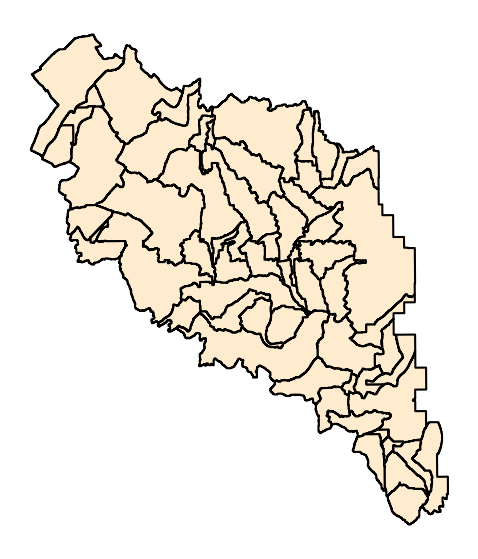

In [12]:

# Identify initial subbasin containing WSC outlet point
point = Point(wsc_dp.Longitude, wsc_dp.Latitude)
#point = wsc_dp_gdf.geometry
basins_gdf['contains_point'] = basins_gdf.geometry.contains(point, align = False)

# wsc_basins = basins_gdf.sjoin(point, how = 'inner', predicate = 'contains')

wsc_basins = basins_gdf[basins_gdf['contains_point'] == True]
dp = wsc_basins['SubId'].values

# for i, row in basins_gdf.iterrows():
#     if row['contains_point'] == True:
#            dp = row['SubId']
           
print(dp)

# Create list containing inital Manning Canal subbasins and its upstream subbasin
for i, row in basins_gdf.iterrows():
    if row['DowSubId'] == dp:
        sub_select = [row['DowSubId'], row['SubId']]

print(sub_select)

# Add subbasins to Manning Canal list if they are connected to previously added subbasins (via DowSubId field)
n = 0
while n == 0:
    for i, row in basins_gdf.iterrows():
        if row['DowSubId'] in sub_select and row['SubId'] not in sub_select:
            sub_select.append(row['SubId'])
            break
    else:
        n = 1
print(sub_select)

# Create geodataframe containing Manning Canal subbasins
mc_gdf = basins_gdf[basins_gdf['SubId'].isin(sub_select)]

# Plot Manning Canal subbasins
f, ax = plt.subplots(1,1,figsize=(7,7))
mc_gdf.plot(ax=ax, color = 'blanchedalmond', edgecolor = 'black', linewidth = 1.5)
ax.axis('off')

## Calculate Routing Parameters

In [39]:
# Calculate time of concentration and time to peak
cn = 63

mc_gdf['BasinsArea_acres'] = mc_gdf['BasArea'] * 0.00024710538
mc_gdf['FlowLength_ft'] = 209 * (mc_gdf['BasinsArea_acres']**0.6)
mc_gdf['BasSlope_prcnt'] = numpy.tan(numpy.radians(mc_gdf['BasSlope'])) * 100
mc_gdf['max_retention'] = (1000 / cn) - 10

mc_gdf['time_of_conc'] = ((mc_gdf['FlowLength_ft']**0.8) * ((mc_gdf['max_retention'] + 1)**0.7)) / (1140 * (mc_gdf['BasSlope_prcnt']**0.5))
mc_gdf['time_to_peak'] = mc_gdf['time_of_conc'] * 0.6

mc_gdf.head()

,SubId,DowSubId,RivSlope,RivLength,BasSlope,BasAspect,BasArea,BkfWidth,BkfDepth,Lake_Cat,...,Shape_Leng,Shape_Area,geometry,contains_point,BasinsArea_acres,FlowLength_ft,BasSlope_prcnt,max_retention,time_of_conc,time_to_peak
0,310013151.0,310015352.0,0.001359,1472.132034,0.139288,101.631184,1020600.0,3.598586,0.178092,0.0,...,0.068457,0.000126,"POLYGON ((-96.60181 49.40316, -96.60346 49.403...",False,252.195751,5770.174473,0.243105,5.873016,7.000884,4.200530
1,310013152.0,310015352.0,0.000777,3362.132034,0.341033,113.693816,5556600.0,1.557162,0.107737,0.0,...,0.174396,0.000688,"POLYGON ((-96.63638 49.39647, -96.63597 49.396...",False,1373.065755,15950.014693,0.595222,5.873016,10.091778,6.055067
2,310013155.0,310013151.0,0.000768,1301.543289,0.094106,59.975058,3028500.0,1.322273,0.100000,0.0,...,0.147896,0.000375,"MULTIPOLYGON (((-96.57027 49.42225, -96.56986 ...",False,748.358643,11081.847094,0.164246,5.873016,14.356245,8.613747
3,310013156.0,310013151.0,0.000496,6743.452378,0.136037,93.606178,18478800.0,3.324347,0.169820,0.0,...,0.382254,0.002289,"POLYGON ((-96.54527 49.37106, -96.54528 49.371...",False,4566.210896,32800.454815,0.237430,5.873016,28.446865,17.068119
4,310013179.0,310013156.0,0.000032,796.690476,0.085525,40.444107,742500.0,1.155956,0.100000,0.0,...,0.078194,0.000092,"POLYGON ((-96.56667 49.36743, -96.56709 49.367...",False,183.475745,4767.530515,0.149269,5.873016,7.669169,4.601501


## Write MC subbasins geodataframe to shapefile

In [38]:
mc_gdf.to_file(DATA_PROCESSED + "Subbasins/mc_clrh_subbasins.shp")

C:\Users\emilito\AppData\Local\Temp\ipykernel_22260\1122881882.py:1: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  mc_gdf.to_file(DATA_PROCESSED + "Subbasins/mc_clrh_subbasins.shp")


## Delineate Upper Manning with Whitebox

In [ ]:
import sys
!{sys.executable} -m pip install whitebox
import whitebox
wbt = whitebox.WhiteboxTools()

import shapely
import rasterio
import rasterio.plot
from osgeo import gdal

In [347]:
# Resample dem

#wbt.set_working_dir("/Users/emilito/Documents/PWA/Data/Raw/manning/DEMs")

#dem = "sr_dem_cgvd28_Resamp_1.tif"
#dem_90m = gdal.Warp('sr_dem_cgvd28_90m.tif', dem, dstSRS= 'EPSG:26914', xRes = 90, yRes =-90, resampleAlg='cubic')

.\whitebox_tools.exe --run="BreachDepressionsLeastCost" --wd="\Users\emilito\Documents\PWA\Data\Raw\manning\DEMs" --dem='sr_dem_cgvd28_Resamp_1.tif' --output='mc_breachdep.tif' --dist='1000' --min_dist --fill -v --compress_rasters=False

*****************************************
* Welcome to BreachDepressionsLeastCost *
* Powered by WhiteboxTools              *
* www.whiteboxgeo.com                   *
*****************************************
Reading data...
Finding pits: 0%
Finding pits: 1%
Finding pits: 2%
Finding pits: 3%
Finding pits: 4%
Finding pits: 5%
Finding pits: 6%
Finding pits: 7%
Finding pits: 8%
Finding pits: 9%
Finding pits: 10%
Finding pits: 11%
Finding pits: 12%
Finding pits: 13%
Finding pits: 14%
Finding pits: 15%
Finding pits: 16%
Finding pits: 17%
Finding pits: 18%
Finding pits: 19%
Finding pits: 20%
Finding pits: 21%
Finding pits: 22%
Finding pits: 23%
Finding pits: 24%
Finding pits: 25%
Finding pits: 26%
Finding pits: 27%
Finding pits: 28%
Finding pits: 29%
Findin

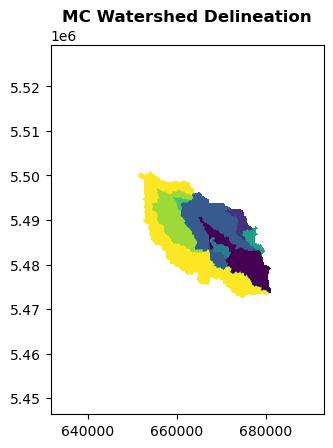

<Axes: title={'center': 'MC Watershed Delineation'}>

In [ ]:
# Set working directory
#wbt.set_working_dir("/Users/emilito/Documents/PWA/Data/Raw/manning/DEMs")

# Fill depressions in DEM
#wbt.fill_depressions(
    #dem = "sr_dem_cgvd28_Resamp_1.tif",
    #output = "mc_filldep.tif",
    #fix_flats=True,
    #flat_increment=None,
    #max_depth=None
#)

# Breach depressions in DEM
wbt.breach_depressions_least_cost(
    dem = "sr_dem_cgvd28_Resamp_1.tif",
    output = "mc_breachdep.tif", 
    dist = 1000, 
    max_cost=None, 
    min_dist=True, 
    flat_increment=None, 
    fill=True
)

# Create flow accumulation raster
wbt.d8_flow_accumulation(
    i = "mc_breachdep.tif", 
    output = "mc_flowaccgrid.tif", 
    out_type="cells", 
    log=False, 
    clip=False, 
    pntr=False, 
    esri_pntr=False
)

# Extract streams from flow accumulation raster
wbt.extract_streams(
    flow_accum='mc_flowaccgrid.tif', 
    output='mc_streams_90000.tif', 
    threshold=90000.000000, 
    zero_background=True, 
)

# Create flow pointer (flow direction) raster
wbt.d8_pointer(
    dem = "mc_breachdep.tif",
    output = "mc_flowpointergrid.tif",
    esri_pntr=False
)

# Snap pour points to stream network
wbt.jenson_snap_pour_points(
    pour_pts = "mc_pp_extract.shp", 
    streams = "mc_streams_90000.tif", 
    output = "mc_pp_snap_2000m.shp", 
    snap_dist = 2000.0
)

# Derive watershed areas
wbt.watershed(
    d8_pntr = 'mc_flowpointergrid.tif', 
    pour_pts = 'mc_pp_snap_2000m.shp', 
    output = 'mc_watershed_90000.tif', 
    esri_pntr=False
)

# Visualize Manning Canal watershed raster
data_name = "/Users/emilito/Documents/PWA/Data/Raw/manning/DEMs/mc_watershed_90000.tif"
tiff = rasterio.open(data_name)
rasterio.plot.show(tiff, title = "MC Watershed Delineation")

In [526]:
# Convert raster watershed output to vector polygons
wbt.raster_to_vector_polygons(
    i = 'mc_watershed_90000.tif', 
    output = 'mc_watershed_90000.shp'
)

.\whitebox_tools.exe --run="RasterToVectorPolygons" --wd="\Users\emilito\Documents\PWA\Data\Raw\manning\DEMs" --input='mc_watershed_90000.tif' --output='mc_watershed_90000.shp' -v --compress_rasters=False

*************************************


* Welcome to RasterToVectorPolygons *
* Powered by WhiteboxTools          *
* www.whiteboxgeo.com               *
*************************************
Reading data...
Clumping polygons: 0%
Clumping polygons: 1%
Clumping polygons: 2%
Clumping polygons: 3%
Clumping polygons: 4%
Clumping polygons: 5%
Clumping polygons: 6%
Clumping polygons: 7%
Clumping polygons: 8%
Clumping polygons: 9%
Clumping polygons: 10%
Clumping polygons: 11%
Clumping polygons: 12%
Clumping polygons: 13%
Clumping polygons: 14%
Clumping polygons: 15%
Clumping polygons: 16%
Clumping polygons: 17%
Clumping polygons: 18%
Clumping polygons: 19%
Clumping polygons: 20%
Clumping polygons: 21%
Clumping polygons: 22%
Clumping polygons: 23%
Clumping polygons: 24%
Clumping polygons: 25%
Clumping polygons: 26%
Clumping polygons: 27%
Clumping polygons: 28%
Clumping polygons: 29%
Clumping polygons: 30%
Clumping polygons: 31%
Clumping polygons: 32%
Clumping polygons: 33%
Clumping polygons: 34%
Clumping polygons: 35%
Clumping polyg

0

## Create BasinMaker Outlet Points

In [14]:
# Read in basinmaker subbasin and rivers shapefiles as geodataframes
#os.getcwd()
#os.chdir('c:\\Users\\emilito\\Documents\\PWA\\Data\\Raw\\manning\\DEMs')

bm_poly = gpd.read_file(DATA_PROCESSED + "Subbasins/mc_clrh_subbasins.shp")
#bm_rivers = gpd.read_file('basinmaker_rivers_MC.shp')
bm_rivers = gpd.read_file(DATA_RAW + "CLRH_RoutingProduct/05OE006/finalcat_info_v1-0_Project.shp")
#wbt_poly = gpd.read_file('mc_watershed.shp')

# Explode basinmaker geodataframe to split multipolygons into separate polygons
bm_poly_exploded = bm_poly.explode(ignore_index=True)

# Create new dataframe of points where basinmaker rivers intersect with basinmaker subbasins
points_df = gpd.GeoDataFrame(columns=['geometry'])

for i, row in bm_rivers.iterrows():
        for x, row in bm_poly_exploded.iterrows():
            poly_coords = bm_poly_exploded.geometry[x]
            line_coords = bm_rivers.geometry[i]
            polin = LineString(list(poly_coords.exterior.coords))
            #intersection
            pt = polin.intersection(line_coords)
            #print(pt.wkt)
            if pt.wkt != 'LINESTRING EMPTY':
                gdf_to_append = gpd.GeoDataFrame({'geometry': pt.wkt, 'SubId': bm_poly_exploded.SubId[x]}, index=[0])
                points_df = pd.concat([points_df, gdf_to_append], ignore_index=True)
#print(points_df)

# Convert points dataframe to geodataframe
geometry = points_df['geometry'].map(shapely.wkt.loads)
points_df = points_df.drop('geometry', axis=1)
points_gdf = gpd.GeoDataFrame(points_df, crs="EPSG:4326", geometry=geometry)
#points_gdf = points_gdf.set_crs(epsg=26914, allow_override=True)

# Explode points geodataframe to split multipoints into separate points
points_gdf_exploded = points_gdf.explode(ignore_index=True)

# Extract basinmaker rivers that intersect with basinmaker subbasins
bm_rivers_intersect = gpd.sjoin(bm_rivers, bm_poly_exploded, op='intersects')

# Plot basinmaker subbasins, rivers, and outlet points
f, ax = plt.subplots(1,1,figsize=(7,7))
bm_poly_exploded.plot(ax=ax, color = 'blanchedalmond', edgecolor = 'black', linewidth = 1.5)
points_gdf.plot(ax=ax, color = 'blue', edgecolor = 'blue')
bm_rivers_intersect.plot(ax=ax, color = 'red', edgecolor = 'red', linewidth = 1.5)
ax.axis('off')


GEOSException: TopologyException: Input geom 1 is invalid: Ring Self-intersection at or near point -96.649247349999939 49.513072462000082 at -96.649247349999939 49.513072462000082

In [497]:
# Write exploded basinmaker geodataframes to shapefiles
bm_poly_exploded.to_file("/Users/emilito/Documents/PWA/Data/Raw/manning/DEMs/bm_poly_exploded.shp")
points_gdf_exploded.to_file("/Users/emilito/Documents/PWA/Data/Raw/manning/DEMs/bm_pp.shp")

## Extract most downstream BasinMaker pourpoint per subbasin

c:\Users\emilito\AppData\Local\anaconda3\envs\gpd_tutorial\lib\site-packages\geopandas\geodataframe.py:1443: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)
C:\Users\emilito\AppData\Local\Temp\ipykernel_24288\2999848644.py:30: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pp_project_select_basins['Elevation'].loc[index] = dem_data[row, colmn]
c:\Users\emilito\AppData\Local\anaconda3\envs\gpd_tutorial\lib\site-packages\geopandas\array.py:1406: UserWarning: CRS not set for some of the concatenation inputs. Setting output's CRS as WGS 8

(-96.95441666664995, -96.47225000034994, 49.35354166300007, 49.66979166300004)

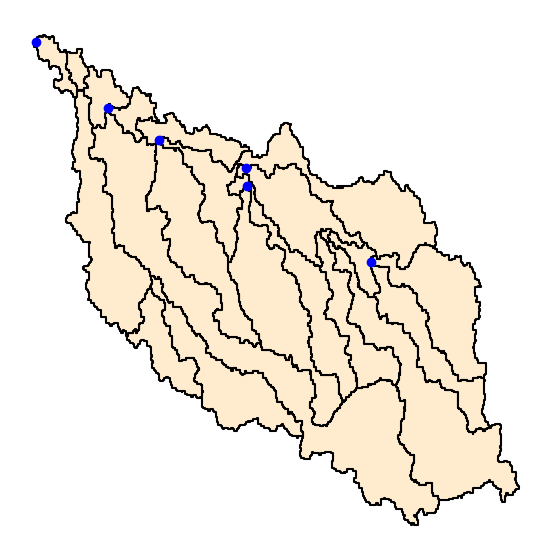

In [524]:
# Read in observation points shapefile
obs_points = gpd.read_file('c:\\Users\\emilito\\Documents\\PWA\\Data\\Raw\\manning\\DEMs\\mc_pp_extract_proj.shp')

# Extract subbasins that contain observation points
bm_extract_basins = gpd.sjoin(bm_poly_exploded, obs_points, predicate='contains').drop_duplicates(subset=['SubId'], keep='first')

# Read in basinmaker pourpoints shapefile
pp = gpd.read_file('c:\\Users\\emilito\\Documents\\PWA\\Data\\Raw\\manning\\DEMs\\bm_pp.shp')

# Project basinmaker pourpoints to EPSG:26914 for processing with dem
pp_project = pp.to_crs(26914)

# Filter out subbasins that do not contain observation points
mask = pp_project['SubId'].isin(bm_extract_basins['SubId'])
pp_project_select_basins = pp_project[mask]

# Add column to pourpoints geodataframe with elevation values
import rasterio
# Create empty column for elevation values
pp_project_select_basins['Elevation'] = 0
# Extract elevation values for each point from dem
for index, row in pp_project_select_basins.iterrows():
    latitude = row['geometry'].y
    longitude = row['geometry'].x
    # Read the dem using rasterio library
    dem = rasterio.open('c:\\Users\\emilito\\Documents\\PWA\\Data\\Raw\\manning\\DEMs\\sr_dem_cgvd28_Resamp_1.tif')
    row, colmn = dem.index(longitude,latitude)
    dem_data = dem.read(1)
    # Add elevation values to geodataframe
    pp_project_select_basins['Elevation'].loc[index] = dem_data[row, colmn]

# Reproject pourpoints back to EPSG:4326
pp_reproject = pp_project_select_basins.to_crs(4326)

# Create geodataframe containing pourpoints with the lowest elevation value per subbasin
dstrm_pt_gdf =gpd.GeoDataFrame(columns=['geometry', 'SubId', 'Elevation'])

for i, row in pp_reproject.iterrows():
    df = pp_reproject.loc[[pp_reproject.loc[pp_reproject.SubId == pp_reproject.SubId[i], 'Elevation'].idxmin()]]
    dstrm_pt_gdf = pd.concat([dstrm_pt_gdf, df], ignore_index=True)

# Remove duplicate subbasin rows
dstrm_pt_no_dups = dstrm_pt_gdf.drop_duplicates(subset=['SubId'], keep='first', ignore_index=True)

# Plot basinmaker subbasins with outlet points
f, ax = plt.subplots(1,1,figsize=(7,7))
bm_poly_exploded.plot(ax=ax, color = 'blanchedalmond', edgecolor = 'black', linewidth = 1.5)
dstrm_pt_no_dups.plot(ax=ax, color = 'blue', edgecolor = 'blue')
ax.axis('off')

In [ ]:
# Write basinmaker outlet points to shapefile
dstrm_pt_no_dups.to_file("/Users/emilito/Documents/PWA/Data/Raw/manning/DEMs/bm_dstrm_pp.shp")